# 🐱🐶 Cat vs Dog Image Classification: End-to-End Analysis with a Basic CNN

**Pipeline:** Data → EDA & Visualization → Preprocessing → Basic CNN → Result Analysis
(Accuracy, Precision, Recall, F1, Confusion Matrix, ROC, AUC)

---

### Dataset at a glance (verified from the uploaded `archive.zip`)
| Property | Value |
|---|---|
| Task | Binary image classification (`cat` vs `dog`) |
| Images | 1,000 (500 cat / 500 dog), perfectly balanced |
| Format | RGB PNG, 512 × 512 px |
| Folder layout | `animals/cat/*.png`, `animals/dog/*.png` |

### How to run (Google Colab)
1. Upload this notebook to Colab (**File → Upload notebook**).
2. **Runtime → Change runtime type → GPU** (T4 is plenty).
3. Click the **📁 Files icon** in the left sidebar, then drag and drop `archive.zip` into it (it lands at `/content/archive.zip`). Wait until the upload finishes (the little circle in the bottom-left of the Files panel disappears).
4. **Runtime → Run all.**

*(Prefer Google Drive? Set `DATA_SOURCE = "drive"` in Section 2.)*

**Convention:** the positive class (label `1`) is **dog**; all precision/recall/F1 numbers are for `dog` unless stated otherwise.

## 1. Setup & Reproducibility

In [ ]:
import os, random, zipfile, hashlib, shutil, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from tqdm import tqdm
from scipy import stats

from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, roc_curve, auc,
                             roc_auc_score, precision_recall_curve, average_precision_score)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})

# --- Auto-save every figure to ./results/ (handy for GitHub README / reports) ---
os.makedirs("results", exist_ok=True)
_fig_n = [0]
_orig_show = plt.show
def _show_and_save(*args, **kwargs):
    for n in plt.get_fignums():
        _fig_n[0] += 1
        plt.figure(n).savefig(f"results/fig_{_fig_n[0]:02d}.png", dpi=150, bbox_inches="tight")
    _orig_show(*args, **kwargs)
plt.show = _show_and_save

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
gpus = tf.config.list_physical_devices("GPU")
print("GPU available:", gpus if gpus else "None (training will be slower. Enable GPU in Runtime settings)")

## 2. Data Loading

Pick where your `archive.zip` is (default works if you dragged the zip into Colab's **Files** panel):
- `"colab_files"`: zip is at `/content/archive.zip` (uploaded via the left Files panel). **Default.**
- `"drive"`: zip is in Google Drive; set `DRIVE_ZIP_PATH`.
- `"upload"`: opens a browser upload dialog (slow for ~377 MB, so prefer the other two).

In [ ]:
DATA_SOURCE    = "colab_files"                      # "colab_files" | "drive" | "upload"
COLAB_ZIP_PATH = "/content/archive.zip"
DRIVE_ZIP_PATH = "/content/drive/MyDrive/archive.zip"
EXTRACT_DIR    = "/content/dataset"

if DATA_SOURCE == "colab_files":
    ZIP_PATH = COLAB_ZIP_PATH
elif DATA_SOURCE == "drive":
    from google.colab import drive
    drive.mount("/content/drive")
    ZIP_PATH = DRIVE_ZIP_PATH
elif DATA_SOURCE == "upload":
    from google.colab import files
    uploaded = files.upload()
    ZIP_PATH = "/content/" + list(uploaded.keys())[0]
else:
    raise ValueError("DATA_SOURCE must be 'colab_files', 'drive' or 'upload'")

if not os.path.isdir(EXTRACT_DIR):
    assert os.path.exists(ZIP_PATH), (
        f"Zip not found at {ZIP_PATH}. Upload archive.zip via the left Files panel "
        "(and wait for the upload to finish), or change DATA_SOURCE / the path above.")
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall(EXTRACT_DIR)
    print("Extracted to", EXTRACT_DIR)
else:
    print("Already extracted, skipping.")

# Locate the folder that directly contains the class sub-folders (cat/, dog/)
DATA_DIR = os.path.join(EXTRACT_DIR, "animals")
if not os.path.isdir(DATA_DIR):
    DATA_DIR = EXTRACT_DIR
print("DATA_DIR :", DATA_DIR)
print("Classes  :", sorted(d for d in os.listdir(DATA_DIR) if os.path.isdir(os.path.join(DATA_DIR, d))))

## 3. Dataset Inventory & Data-Quality Audit

Before any modelling, an analyst should confirm: *How many images per class? Are all files readable?
Are sizes/modes consistent? Are there exact duplicates?* A single pass collects per-image metadata and basic
image statistics that we reuse in the EDA below.

In [1]:
IMG_EXT = (".png", ".jpg", ".jpeg", ".bmp", ".webp")

records = []
for cls in sorted(os.listdir(DATA_DIR)):
    cdir = os.path.join(DATA_DIR, cls)
    if not os.path.isdir(cdir):
        continue
    for fn in sorted(os.listdir(cdir)):
        if fn.lower().endswith(IMG_EXT):
            records.append({"path": os.path.join(cdir, fn), "label": cls})

df = pd.DataFrame(records)
print(f"Total images found: {len(df)}")

def inspect_image(path):
    out = {"ok": True}
    try:
        with Image.open(path) as im:
            im.verify()                                   # structural integrity check
        with Image.open(path) as im:
            out.update(width=im.width, height=im.height, mode=im.mode)
            small = np.asarray(im.convert("RGB").resize((128, 128)), dtype=np.float32)
        gray = small.mean(axis=2)
        # sharpness proxy: mean absolute horizontal+vertical gradient
        sharp = np.abs(np.diff(gray, axis=0)).mean() + np.abs(np.diff(gray, axis=1)).mean()
        out.update(mean_r=small[..., 0].mean(), mean_g=small[..., 1].mean(), mean_b=small[..., 2].mean(),
                   brightness=gray.mean(), contrast=gray.std(), sharpness=sharp)
        with open(path, "rb") as f:
            out["md5"] = hashlib.md5(f.read()).hexdigest()
        out["file_kb"] = os.path.getsize(path) / 1024
    except Exception as e:
        out.update(ok=False, error=str(e))
    return out

meta = pd.DataFrame([inspect_image(p) for p in tqdm(df["path"], desc="Auditing images")])
df = pd.concat([df, meta], axis=1)

print("\n===== DATA QUALITY REPORT =====")
print(f"Corrupted / unreadable files : {(~df['ok']).sum()}")
print(f"Missing values (metadata)    : {int(df.drop(columns=[c for c in ['error'] if c in df]).isna().sum().sum())}")
print(f"Exact duplicate files (MD5)  : {df['md5'].duplicated().sum()}")
print(f"Unique image sizes (WxH)     : {df.groupby(['width','height']).ngroups} -> {sorted(set(zip(df.width, df.height)))}")
print(f"Unique colour modes          : {df['mode'].unique().tolist()}")
print("\nClass distribution:")
print(df["label"].value_counts().to_frame("count").assign(percent=lambda d: (100 * d["count"] / d["count"].sum()).round(1)))

df = df[df["ok"]].drop(columns=["ok"] + (["error"] if "error" in df else [])).reset_index(drop=True)

Total images found: 1000

===== DATA QUALITY REPORT =====
Corrupted / unreadable files : 0
Missing values (metadata)    : 0
Exact duplicate files (MD5)  : 0
Unique image sizes (WxH)     : 1 -> [(512, 512)]
Unique colour modes          : ['RGB']

Class distribution:
       count  percent
label                
cat      500     50.0
dog      500     50.0


## 4. Exploratory Data Analysis & Visualization

### 4.1 Class balance

Imbalance ratio (majority/minority): 1.00  ->  balanced, no resampling or class weights needed.


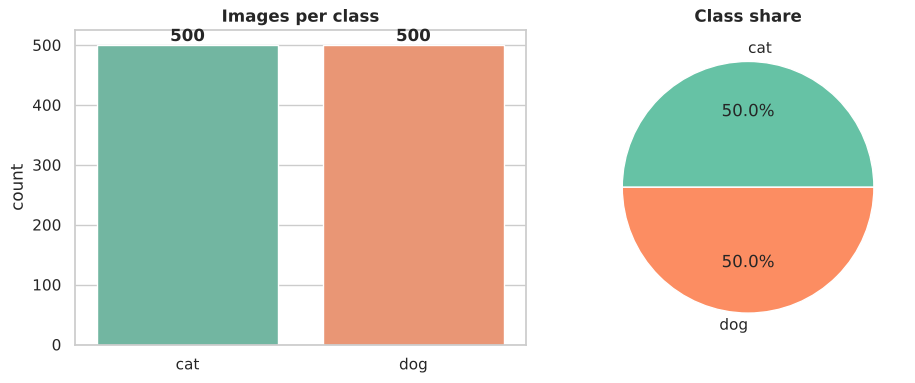

In [2]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
order = sorted(df["label"].unique())
sns.countplot(data=df, x="label", order=order, palette="Set2", ax=ax[0])
for p in ax[0].patches:
    ax[0].annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                   ha="center", va="bottom", fontweight="bold")
ax[0].set_title("Images per class"); ax[0].set_xlabel("")
df["label"].value_counts().reindex(order).plot.pie(autopct="%1.1f%%", colors=sns.color_palette("Set2"), ax=ax[1], ylabel="")
ax[1].set_title("Class share")
plt.tight_layout(); plt.show()

imbalance = df["label"].value_counts().max() / df["label"].value_counts().min()
print(f"Imbalance ratio (majority/minority): {imbalance:.2f}  ->  "
      + ("balanced, no resampling or class weights needed." if imbalance < 1.5 else "consider class weights."))

### 4.2 Visual inspection of random samples

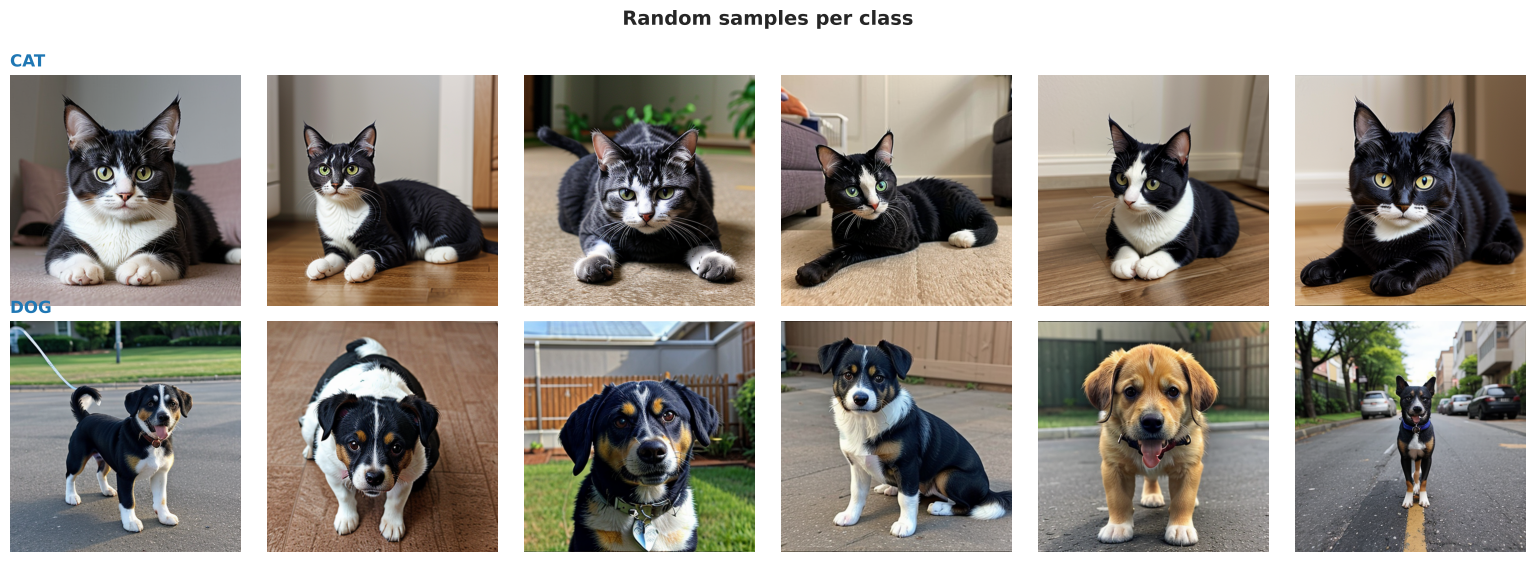

In [3]:
def show_samples(n_per_class=6, seed=SEED):
    classes = sorted(df["label"].unique())
    rng = np.random.RandomState(seed)
    fig, axes = plt.subplots(len(classes), n_per_class, figsize=(2.6 * n_per_class, 2.8 * len(classes)))
    for r, cls in enumerate(classes):
        paths = df[df.label == cls]["path"].values
        for c, p in enumerate(rng.choice(paths, n_per_class, replace=False)):
            axes[r, c].imshow(Image.open(p).convert("RGB"))
            axes[r, c].axis("off")
            if c == 0:
                axes[r, c].set_title(cls.upper(), loc="left", fontsize=12, color="tab:blue")
    plt.suptitle("Random samples per class", fontsize=14, fontweight="bold", y=1.0)
    plt.tight_layout(); plt.show()

show_samples()

### 4.3 Image properties: resolution, colour mode, file size
All images should share one resolution and colour mode. If so, no cropping/padding logic is needed. Only a uniform resize.

      width             height             file_kb              
        min   mean  max    min   mean  max     min   mean    max
label                                                           
cat     512  512.0  512    512  512.0  512   287.7  356.1  469.7
dog     512  512.0  512    512  512.0  512   302.2  380.8  479.4


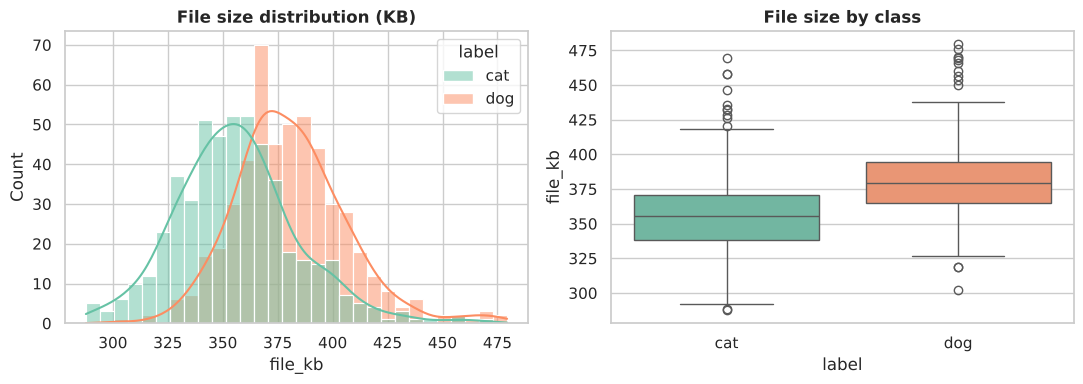

In [4]:
print(df.groupby("label")[["width", "height", "file_kb"]].agg(["min", "mean", "max"]).round(1))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(data=df, x="file_kb", hue="label", kde=True, bins=30, palette="Set2", ax=ax[0])
ax[0].set_title("File size distribution (KB)")
sns.boxplot(data=df, x="label", y="file_kb", palette="Set2", ax=ax[1])
ax[1].set_title("File size by class")
plt.tight_layout(); plt.show()

### 4.4 Low-level image statistics by class
If simple statistics (brightness, contrast, colour balance, sharpness) already separate the classes, a model could
"cheat" on them instead of learning animal features. This section checks for that kind of **shortcut risk**.

single_feature_AUC ~ 0.5 means the feature carries almost no class signal; far from 0.5 flags a potential shortcut.


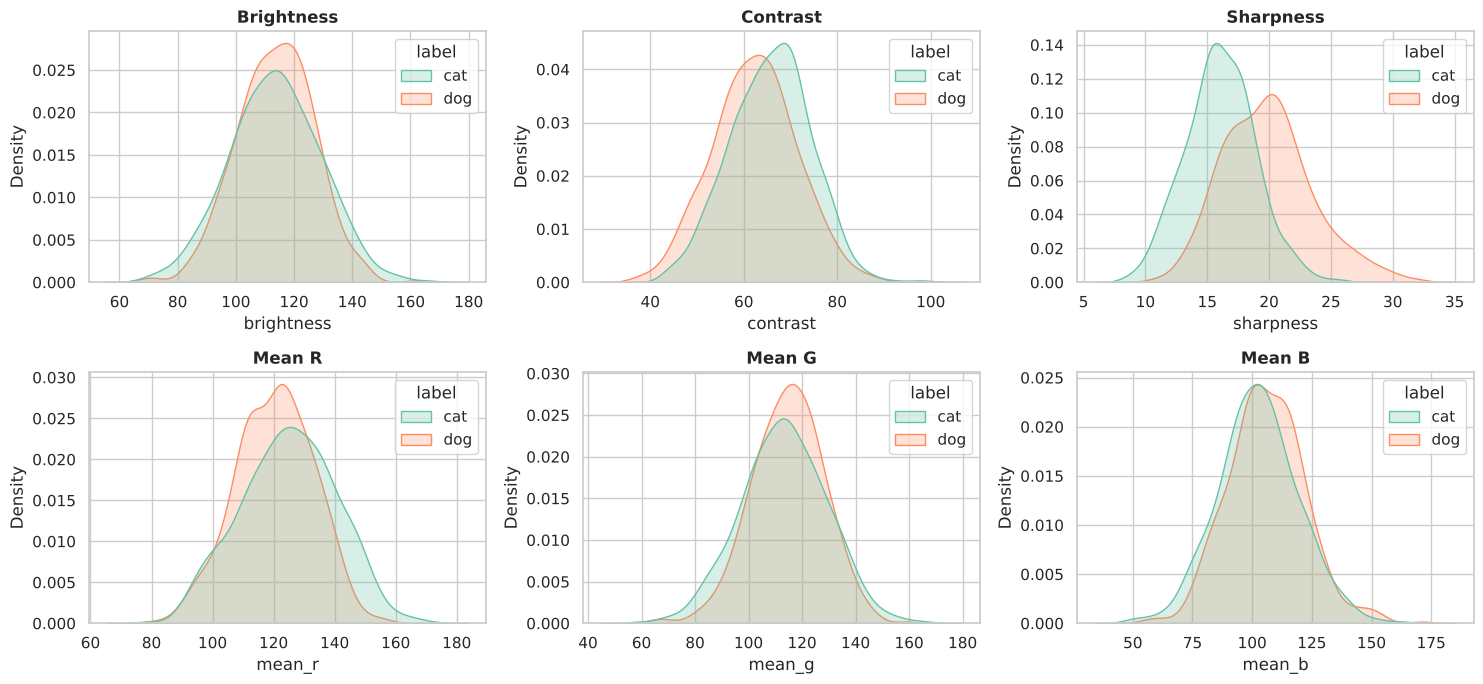

,cat_mean,dog_mean,p_value,single_feature_AUC
feature,,,,
brightness,113.452003,113.568497,0.7867,0.5049
contrast,65.650002,62.324299,0.0000,0.3913
sharpness,16.051701,19.853300,0.0000,0.7959
mean_r,124.796997,120.230797,0.0000,0.4103
mean_g,113.058403,114.562599,0.0855,0.5314
mean_b,102.500702,105.912201,0.0013,0.5589


In [5]:
feats = ["brightness", "contrast", "sharpness", "mean_r", "mean_g", "mean_b"]

fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, f in zip(axes.ravel(), feats):
    sns.kdeplot(data=df, x=f, hue="label", fill=True, common_norm=False, palette="Set2", ax=ax)
    ax.set_title(f.replace("_", " ").title())
plt.tight_layout(); plt.show()

# Statistical comparison + a "single-feature classifier" AUC as an effect-size measure
cat, dog = df[df.label == "cat"], df[df.label == "dog"]
rows = []
for f in feats:
    u, p = stats.mannwhitneyu(cat[f], dog[f], alternative="two-sided")
    rows.append({"feature": f, "cat_mean": cat[f].mean(), "dog_mean": dog[f].mean(),
                 "p_value": p, "single_feature_AUC": roc_auc_score((df.label == "dog").astype(int), df[f])})
stat_df = pd.DataFrame(rows).set_index("feature").round(4)
display(stat_df)
print("single_feature_AUC ~ 0.5 means the feature carries almost no class signal; far from 0.5 flags a potential shortcut.")

### 4.5 Colour channels and average images

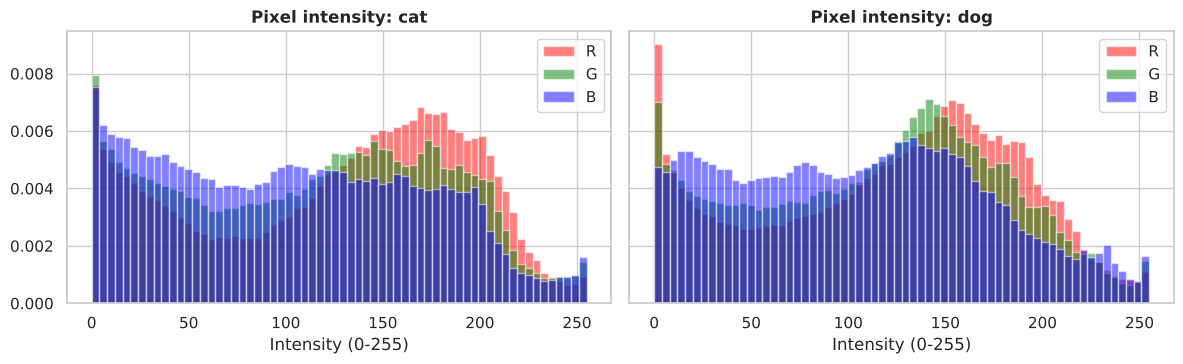

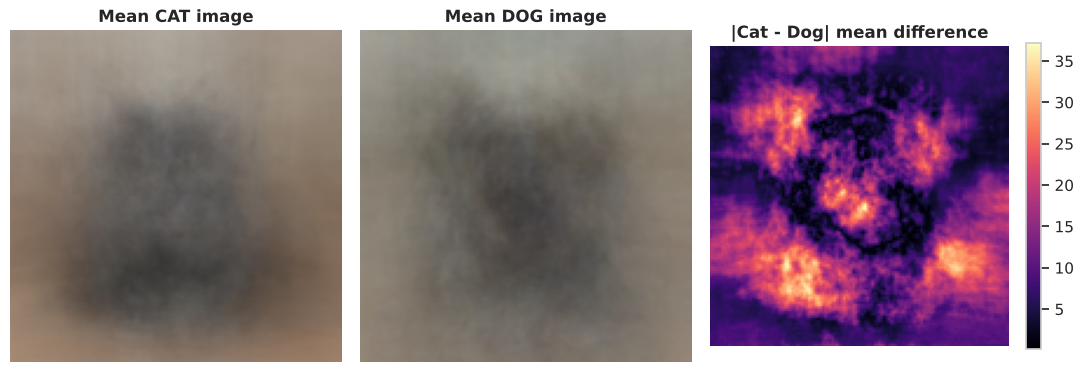

In [6]:
# Pixel-intensity histograms per channel (sample of 100 images/class at 64x64 to keep it fast)
rng = np.random.RandomState(SEED)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, cls in zip(axes, ["cat", "dog"]):
    paths = rng.choice(df[df.label == cls]["path"].values, 100, replace=False)
    arr = np.stack([np.asarray(Image.open(p).convert("RGB").resize((64, 64))) for p in paths])
    for i, (ch, col) in enumerate(zip("RGB", ["red", "green", "blue"])):
        ax.hist(arr[..., i].ravel(), bins=64, range=(0, 255), alpha=0.5, color=col, label=ch, density=True)
    ax.set_title(f"Pixel intensity: {cls}"); ax.set_xlabel("Intensity (0-255)"); ax.legend()
plt.tight_layout(); plt.show()

# Mean image per class
fig, axes = plt.subplots(1, 3, figsize=(11, 3.8))
means = {}
for cls in ["cat", "dog"]:
    paths = df[df.label == cls]["path"].values[:200]
    means[cls] = np.mean([np.asarray(Image.open(p).convert("RGB").resize((128, 128)), dtype=np.float32) for p in paths], axis=0)
axes[0].imshow(means["cat"].astype(np.uint8)); axes[0].set_title("Mean CAT image")
axes[1].imshow(means["dog"].astype(np.uint8)); axes[1].set_title("Mean DOG image")
diff = np.abs(means["cat"] - means["dog"]).mean(axis=2)
im = axes[2].imshow(diff, cmap="magma"); axes[2].set_title("|Cat - Dog| mean difference")
plt.colorbar(im, ax=axes[2], fraction=0.046)
for a in axes: a.axis("off")
plt.tight_layout(); plt.show()

### 4.6 EDA takeaways
- **Quality:** 1,000 readable files, 0 corrupted, 0 exact duplicates, one resolution (512×512) and one colour mode (RGB). A plain resize is all the geometry handling needed.
- **Balance:** exactly 500 cats / 500 dogs, so accuracy is a fair headline metric (we still report precision, recall, F1 and AUC).
- **Colour & brightness:** brightness is virtually identical across classes (single-feature AUC ≈ 0.50) and the colour channels are only weakly informative (AUC ≈ 0.41 to 0.56).
- **Sharpness is the notable signal:** dog images have higher edge/gradient energy (sharpness single-feature AUC ≈ 0.80), and dog files are slightly larger on disk (≈ 381 KB vs 356 KB, consistent with more detail). A CNN may partly exploit texture and sharpness rather than anatomy alone. Keep this in mind when interpreting results, and consider Grad-CAM (Section 8) to verify what the model attends to.
- **Background / scene shortcut (visual observation):** in the random samples above, cats are mostly photographed *indoors* (floors, sofas, walls) while dogs are mostly *outdoors* (roads, grass, fences). A CNN can reach high accuracy by learning the scene instead of the animal. This is the biggest risk to how far the results generalise, so use Grad-CAM and test on real photos with swapped backgrounds (Section 8).
- **File names:** they contain generation *seeds* (e.g. `00000-4122619873.png`), which hints the images may be **AI-generated** in batches. We never use file names as features. Consecutive seeds can produce similar images, so Section 5.3 checks for near-duplicates leaking across splits (none were found at the 0.95 threshold).

## 5. Data Preprocessing

Steps: **(1)** resize 512 → 128 px (keeps detail while making a basic CNN trainable in minutes),
**(2)** encode labels (`cat = 0`, `dog = 1`), **(3)** stratified **70 / 15 / 15** train/val/test split,
**(4)** leakage check, **(5)** build `tf.data` pipelines.
Pixel scaling (÷255) and augmentation live *inside* the model, so train/inference preprocessing can never drift apart.

### 5.1 Resize & label encoding

In [7]:
IMG_SIZE = (128, 128)
CLASS_NAMES = ["cat", "dog"]                 # index = label
label_map = {c: i for i, c in enumerate(CLASS_NAMES)}

def load_resized(path):
    with Image.open(path) as im:
        return np.asarray(im.convert("RGB").resize(IMG_SIZE, Image.BILINEAR), dtype=np.uint8)

X = np.stack([load_resized(p) for p in tqdm(df["path"], desc="Loading & resizing")])   # uint8 keeps RAM small
y = df["label"].map(label_map).values.astype("int32")

print("X shape:", X.shape, "| dtype:", X.dtype, f"| {X.nbytes/1e6:.1f} MB")
print("y shape:", y.shape, "| class counts:", dict(zip(CLASS_NAMES, np.bincount(y))))

X shape: (1000, 128, 128, 3) | dtype: uint8 | 49.2 MB
y shape: (1000,) | class counts: {'cat': np.int64(500), 'dog': np.int64(500)}


### 5.2 Stratified train / validation / test split

,images,cat,dog
split,,,
train,700,350,350
val,150,75,75
test,150,75,75


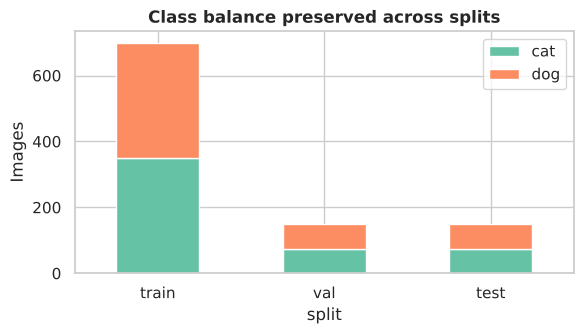

In [8]:
idx = np.arange(len(X))
idx_train, idx_tmp = train_test_split(idx, test_size=0.30, stratify=y, random_state=SEED)
idx_val, idx_test  = train_test_split(idx_tmp, test_size=0.50, stratify=y[idx_tmp], random_state=SEED)

X_train, y_train = X[idx_train], y[idx_train]
X_val,   y_val   = X[idx_val],   y[idx_val]
X_test,  y_test  = X[idx_test],  y[idx_test]

split_summary = pd.DataFrame({
    "split": ["train", "val", "test"],
    "images": [len(y_train), len(y_val), len(y_test)],
    "cat": [(y_train == 0).sum(), (y_val == 0).sum(), (y_test == 0).sum()],
    "dog": [(y_train == 1).sum(), (y_val == 1).sum(), (y_test == 1).sum()],
}).set_index("split")
display(split_summary)

split_summary[["cat", "dog"]].plot(kind="bar", stacked=True, color=sns.color_palette("Set2"), figsize=(6, 3.5))
plt.title("Class balance preserved across splits"); plt.ylabel("Images"); plt.xticks(rotation=0)
plt.tight_layout(); plt.show()

### 5.3 Leakage check: near-duplicate images across splits
Consecutive generation seeds can yield near-identical pictures. If a test image has a near-twin in the training
set, test metrics will be optimistically biased. We compare 32×32 grayscale thumbnails by Pearson correlation.

Test images with a near-duplicate (corr > 0.95) in train: 0 / 150
Val  images with a near-duplicate (corr > 0.95) in train: 0 / 150


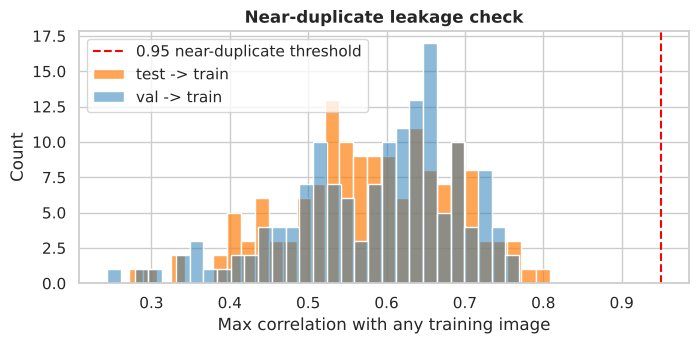

In [9]:
def thumb_vectors(arr):
    g = arr.astype(np.float32).mean(axis=-1)                         # grayscale
    g = g.reshape(len(g), 32, 4, 32, 4).mean(axis=(2, 4)).reshape(len(g), -1)   # 128 -> 32 block-average
    g = g - g.mean(axis=1, keepdims=True)
    return g / (np.linalg.norm(g, axis=1, keepdims=True) + 1e-8)

V_train, V_val, V_test = map(thumb_vectors, (X_train, X_val, X_test))
max_sim_test = (V_test @ V_train.T).max(axis=1)
max_sim_val  = (V_val  @ V_train.T).max(axis=1)

plt.figure(figsize=(7, 3.6))
sns.histplot(max_sim_test, bins=30, color="tab:orange", label="test -> train", alpha=0.7)
sns.histplot(max_sim_val,  bins=30, color="tab:blue",   label="val -> train",  alpha=0.5)
plt.axvline(0.95, color="red", ls="--", label="0.95 near-duplicate threshold")
plt.xlabel("Max correlation with any training image"); plt.title("Near-duplicate leakage check"); plt.legend()
plt.tight_layout(); plt.show()
print(f"Test images with a near-duplicate (corr > 0.95) in train: {(max_sim_test > 0.95).sum()} / {len(max_sim_test)}")
print(f"Val  images with a near-duplicate (corr > 0.95) in train: {(max_sim_val  > 0.95).sum()} / {len(max_sim_val)}")

### 5.4 `tf.data` pipelines

In [ ]:
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

def make_ds(X_, y_, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((X_, y_.astype("float32")))
    if shuffle:
        ds = ds.shuffle(len(X_), seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds = make_ds(X_train, y_train, shuffle=True)
val_ds   = make_ds(X_val,   y_val)
test_ds  = make_ds(X_test,  y_test)      # not shuffled -> predictions align with y_test

# Visual check of what augmentation does to a single training image
aug_preview = keras.Sequential([layers.RandomFlip("horizontal"), layers.RandomRotation(0.08), layers.RandomZoom(0.1)])
fig, axes = plt.subplots(1, 6, figsize=(14, 2.6))
axes[0].imshow(X_train[0]); axes[0].set_title("Original")
for a in axes[1:]:
    a.imshow(aug_preview(X_train[0:1].astype("float32"), training=True)[0].numpy().astype("uint8")); a.set_title("Augmented")
for a in axes: a.axis("off")
plt.tight_layout(); plt.show()

## 6. Model: Basic CNN

Architecture (deliberately simple, a clean baseline):

`Input → Augmentation → Rescale(1/255) → [Conv3×3 → BatchNorm → MaxPool → Dropout] × 4 → GlobalAvgPool → Dense(64) → Dropout(0.5) → Dense(1, sigmoid)`

- **BatchNorm** stabilises/accelerates training; **Dropout** and **augmentation** fight overfitting (only 700 training images).
- **Global average pooling** instead of `Flatten` keeps the parameter count small.
- **Sigmoid + binary cross-entropy** is the right pairing for one binary output.

In [ ]:
def build_cnn(input_shape=(*IMG_SIZE, 3)):
    augmentation = keras.Sequential([
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.08),
        layers.RandomZoom(0.1),
    ], name="augmentation")

    inputs = keras.Input(shape=input_shape)
    x = augmentation(inputs)                    # active only during training
    x = layers.Rescaling(1.0 / 255)(x)

    for filters in (32, 64, 128, 128):
        x = layers.Conv2D(filters, 3, padding="same", activation="relu")(x)
        x = layers.BatchNormalization()(x)
        x = layers.MaxPooling2D()(x)
        x = layers.Dropout(0.25)(x)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(64, activation="relu")(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(1, activation="sigmoid")(x)
    return keras.Model(inputs, outputs, name="basic_cnn")

model = build_cnn()
model.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss="binary_crossentropy",
    metrics=["accuracy",
             keras.metrics.AUC(name="auc"),
             keras.metrics.Precision(name="precision"),
             keras.metrics.Recall(name="recall")],
)
model.summary()

### 6.1 Training
`EarlyStopping` halts when validation loss stops improving (and restores the best weights);
`ReduceLROnPlateau` lowers the learning rate on plateaus; `ModelCheckpoint` saves the best model.

In [ ]:
callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True, verbose=1),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, min_lr=1e-6, verbose=1),
    keras.callbacks.ModelCheckpoint("best_cnn.keras", monitor="val_loss", save_best_only=True),
]

history = model.fit(train_ds, validation_data=val_ds, epochs=50, callbacks=callbacks, verbose=2)

### 6.2 Learning curves

In [ ]:
hist = pd.DataFrame(history.history)
best_epoch = hist["val_loss"].idxmin()

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (m, title) in zip(axes, [("loss", "Loss"), ("accuracy", "Accuracy"), ("auc", "AUC")]):
    ax.plot(hist[m], label="train", lw=2); ax.plot(hist[f"val_{m}"], label="validation", lw=2)
    ax.axvline(best_epoch, color="gray", ls="--", label=f"best epoch ({best_epoch + 1})")
    ax.set_title(title); ax.set_xlabel("Epoch"); ax.legend()
plt.tight_layout(); plt.show()

gap = hist.loc[best_epoch, "accuracy"] - hist.loc[best_epoch, "val_accuracy"]
print(f"At best epoch: train acc = {hist.loc[best_epoch, 'accuracy']:.3f}, val acc = {hist.loc[best_epoch, 'val_accuracy']:.3f}, gap = {gap:+.3f}")

## 7. Result Analysis

All headline numbers below are computed on the **held-out test set** that the model never saw during training
or model selection. Predictions are probabilities of `dog`; the default decision threshold is **0.5**.

In [ ]:
THRESHOLD = 0.5

def predict_probs(ds):
    return model.predict(ds, verbose=0).ravel()

p_train, p_val, p_test = predict_probs(make_ds(X_train, y_train)), predict_probs(val_ds), predict_probs(test_ds)
y_pred_test = (p_test >= THRESHOLD).astype(int)

def metric_row(y_true, p, thr=THRESHOLD):
    yp = (p >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, yp).ravel()
    return {"Accuracy": accuracy_score(y_true, yp),
            "Precision": precision_score(y_true, yp),
            "Recall (Sensitivity)": recall_score(y_true, yp),
            "Specificity": tn / (tn + fp),
            "F1-score": f1_score(y_true, yp),
            "ROC AUC": roc_auc_score(y_true, p)}

results = pd.DataFrame({"Train": metric_row(y_train, p_train),
                        "Validation": metric_row(y_val, p_val),
                        "Test": metric_row(y_test, p_test)}).T.round(4)
display(results.style.background_gradient(cmap="Greens", axis=None).format("{:.4f}"))

### 7.1 Accuracy, Precision, Recall, F1: per-class report

In [ ]:
print(classification_report(y_test, y_pred_test, target_names=[c.upper() for c in CLASS_NAMES], digits=4))

**How to read these**
- **Accuracy**: share of all test images classified correctly (valid headline metric here because classes are balanced).
- **Precision (dog)**: of images predicted *dog*, how many truly are dogs → penalises false alarms (cats called dogs).
- **Recall (dog)**: of all real dogs, how many were found → penalises misses (dogs called cats).
- **F1**: harmonic mean of precision and recall; low if either is low.

### 7.2 Confusion matrix

In [ ]:
cm = confusion_matrix(y_test, y_pred_test)
cm_norm = confusion_matrix(y_test, y_pred_test, normalize="true")
labels = [c.upper() for c in CLASS_NAMES]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels, cbar=False, ax=axes[0], annot_kws={"size": 16})
axes[0].set_title("Confusion matrix (counts)")
sns.heatmap(cm_norm, annot=True, fmt=".1%", cmap="Blues", xticklabels=labels, yticklabels=labels, cbar=False, ax=axes[1], annot_kws={"size": 16})
axes[1].set_title("Confusion matrix (row-normalised = recall per class)")
for a in axes: a.set_xlabel("Predicted"); a.set_ylabel("Actual")
plt.tight_layout(); plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"TN (cat->cat) = {tn} | FP (cat->dog) = {fp} | FN (dog->cat) = {fn} | TP (dog->dog) = {tp}")

### 7.3 ROC curve & AUC (plus Precision-Recall curve)

In [ ]:
fpr, tpr, roc_thr = roc_curve(y_test, p_test)
roc_auc = auc(fpr, tpr)
youden_idx = np.argmax(tpr - fpr)                     # point maximising TPR - FPR
best_thr = roc_thr[youden_idx]

prec, rec, _ = precision_recall_curve(y_test, p_test)
ap = average_precision_score(y_test, p_test)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].plot(fpr, tpr, lw=2.5, color="tab:blue", label=f"CNN (AUC = {roc_auc:.4f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=1, label="Random guess (AUC = 0.5)")
op_fpr = fp / (fp + tn); op_tpr = tp / (tp + fn)
axes[0].scatter(op_fpr, op_tpr, s=90, color="red", zorder=5, label=f"Threshold {THRESHOLD}")
axes[0].scatter(fpr[youden_idx], tpr[youden_idx], s=90, color="green", marker="*", zorder=5, label=f"Youden-optimal thr = {best_thr:.2f}")
axes[0].fill_between(fpr, tpr, alpha=0.12, color="tab:blue")
axes[0].set(xlabel="False Positive Rate (1 - Specificity)", ylabel="True Positive Rate (Recall)", title="ROC curve")
axes[0].legend(loc="lower right")

axes[1].plot(rec, prec, lw=2.5, color="tab:purple", label=f"CNN (AP = {ap:.4f})")
axes[1].axhline(y_test.mean(), color="k", ls="--", lw=1, label=f"Baseline (prevalence = {y_test.mean():.2f})")
axes[1].set(xlabel="Recall", ylabel="Precision", title="Precision-Recall curve", ylim=(0, 1.02))
axes[1].legend(loc="lower left")
plt.tight_layout(); plt.show()

print(f"ROC AUC = {roc_auc:.4f}  |  Average Precision = {ap:.4f}")

**AUC interpretation:** it is the probability that a randomly chosen *dog* image gets a higher score than a randomly
chosen *cat* image. 0.5 = chance, 1.0 = perfect ranking. AUC is threshold-independent, so it tells you about the
quality of the model's *scores*, while accuracy/precision/recall describe one particular threshold.

### 7.4 Threshold analysis

In [ ]:
thr_grid = np.linspace(0.05, 0.95, 91)
rows = []
for t in thr_grid:
    yp = (p_test >= t).astype(int)
    rows.append({"threshold": t,
                 "precision": precision_score(y_test, yp, zero_division=0),
                 "recall": recall_score(y_test, yp),
                 "f1": f1_score(y_test, yp, zero_division=0),
                 "accuracy": accuracy_score(y_test, yp)})
thr_df = pd.DataFrame(rows).set_index("threshold")

ax = thr_df.plot(figsize=(9, 4.2), lw=2)
best_f1_thr = thr_df["f1"].idxmax()
ax.axvline(THRESHOLD, color="gray", ls="--", label="default 0.5")
ax.axvline(best_f1_thr, color="green", ls=":", label=f"best-F1 thr = {best_f1_thr:.2f}")
ax.set_title("Metrics vs decision threshold (test set)"); ax.set_ylabel("score"); ax.legend()
plt.tight_layout(); plt.show()
print("Note: choosing a threshold on the test set is only for illustration. In practice, pick it on the validation set.")

### 7.5 Prediction confidence & uncertainty of the estimates

In [ ]:
# Confidence distribution by true class
plt.figure(figsize=(8, 3.8))
sns.histplot(x=p_test, hue=np.array(CLASS_NAMES)[y_test], bins=25, palette="Set2", multiple="layer", alpha=0.65)
plt.axvline(THRESHOLD, color="red", ls="--")
plt.xlabel("Predicted probability of DOG"); plt.title("Score distribution by true class (good separation = two clear humps)")
plt.tight_layout(); plt.show()

# Bootstrap 95% confidence intervals: the test set is small, so point estimates are noisy
rng = np.random.RandomState(SEED)
boot = {"Accuracy": [], "F1-score": [], "ROC AUC": []}
for _ in range(1000):
    i = rng.randint(0, len(y_test), len(y_test))
    if len(np.unique(y_test[i])) < 2:
        continue
    yp = (p_test[i] >= THRESHOLD).astype(int)
    boot["Accuracy"].append(accuracy_score(y_test[i], yp))
    boot["F1-score"].append(f1_score(y_test[i], yp))
    boot["ROC AUC"].append(roc_auc_score(y_test[i], p_test[i]))
ci = pd.DataFrame({k: [np.mean(v), *np.percentile(v, [2.5, 97.5])] for k, v in boot.items()},
                  index=["bootstrap mean", "95% CI low", "95% CI high"]).T.round(4)
display(ci)

### 7.6 Error analysis: what does the model get wrong?

In [ ]:
wrong = np.where(y_pred_test != y_test)[0]
print(f"Misclassified test images: {len(wrong)} / {len(y_test)}")

if len(wrong):
    # most confident mistakes first
    wrong = wrong[np.argsort(-np.abs(p_test[wrong] - 0.5))][:10]
    cols = min(5, len(wrong)); rows_n = int(np.ceil(len(wrong) / cols))
    fig, axes = plt.subplots(rows_n, cols, figsize=(3 * cols, 3.2 * rows_n), squeeze=False)
    for a in axes.ravel(): a.axis("off")
    for a, i in zip(axes.ravel(), wrong):
        a.imshow(X_test[i])
        a.set_title(f"True: {CLASS_NAMES[y_test[i]]}\nPred: {CLASS_NAMES[y_pred_test[i]]} (p_dog={p_test[i]:.2f})",
                    fontsize=9, color="crimson")
    plt.suptitle("Most confident misclassifications", fontweight="bold")
    plt.tight_layout(); plt.show()

## 8. Final Summary

In [ ]:
t = results.loc["Test"]
print("=" * 58)
print("FINAL TEST-SET SUMMARY (positive class = DOG)")
print("=" * 58)
for k, v in t.items():
    print(f"{k:<24}: {v:.4f}")
print("-" * 58)
print(f"Confusion matrix  -> TN={tn}  FP={fp}  FN={fn}  TP={tp}")
print(f"Train-vs-test accuracy gap: {results.loc['Train','Accuracy'] - t['Accuracy']:+.4f}")
print("=" * 58)

### How to write up your findings
Use the outputs above to answer these questions in your report:

1. **Overall performance:** how do accuracy, F1 and AUC on the test set compare? Do the bootstrap intervals (7.5) show how much to trust them?
2. **Error profile:** is the model biased toward one class? Compare precision vs recall and the FP vs FN counts in the confusion matrix.
3. **Generalisation:** how large is the train-vs-validation/test gap (6.2 and the results table)? A big gap signals overfitting.
4. **Threshold:** does moving the threshold (7.4) buy a meaningful gain, or is 0.5 already near-optimal?
5. **Failure modes:** what do the misclassified images (7.6) have in common (pose, lighting, background, breed)?

### Limitations
- **Small dataset (1,000 images):** the test set has only 150 images, so each mistake moves accuracy by ~0.7 pp. Treat results as indicative, not definitive.
- **Single random split:** for firmer estimates use stratified **k-fold cross-validation**.
- **Possible synthetic origin / batch similarity:** see the leakage check (5.3). Near-duplicates across splits inflate scores.
- **Resolution:** downsizing to 128 px discards fine detail.

### Suggested next steps
- **Transfer learning** (e.g. `MobileNetV2` / `EfficientNetB0` pretrained on ImageNet), which typically gives a large gain on small datasets.
- **Explainability:** Grad-CAM to confirm the model looks at the animal and not the background.
- **Robustness:** test on real-world cat/dog photos to check generalisation beyond this dataset's style.
- **Hyper-parameter tuning:** depth, filters, dropout, learning rate (e.g. KerasTuner).

## 9. Export Figures & Publish to GitHub

Run the next cell to download **all figures** (`results/fig_01.png`, `fig_02.png`, ...) as one zip, ready to embed in a GitHub `README.md`.

**To make the notebook look great on GitHub:**
1. Run **Runtime → Run all** *until the end* so every cell has its output.
2. **File → Save a copy in GitHub** (pushes directly), or **File → Download → Download .ipynb** and commit that file. Do **not** clear outputs: GitHub renders the saved charts and tables.
3. Optional: add the PNGs from the zip to your repo (e.g. `images/`) and show them in your README with `![ROC curve](images/fig_20.png)`.

In [ ]:
DOWNLOAD_FIGURES = True      # set False to skip the browser download

shutil.make_archive("results_figures", "zip", "results")
print(f"Saved {len(os.listdir('results'))} figures in ./results  ->  results_figures.zip")
if DOWNLOAD_FIGURES:
    try:
        from google.colab import files
        files.download("results_figures.zip")
    except Exception as e:
        print("Download skipped:", e)